# A Window On The Deposited Energy

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.9.0

**Author**: Mateusz Jakub Bała

## About

A detector that cannot tell processes apart still measures energy, and the
first cut of many analyses of annihilation gammas is a window on it: keep the
hits that deposited between 200 and 320 keV. Below the window lies the noise
and the small scatterings; above it, up to the Compton edge, the scatterings
that turned the gamma almost back; and at 511 keV, the absorptions.

This notebook puts that window into an analysis - on every hit, on the first
hit of every track, and on both annihilation gammas of an event - and looks at
what it really keeps, which is not only Compton scatterings.

## What will you learn from this notebook

- write an energy window in keV and give it to an analysis, which reads MeV
- keep the hits inside a window, or the tracks whose first hit is inside it
- ask for events in which both annihilation gammas first deposited inside the
  window, and read their energies from a table
- say which ends of the window belong to it
- know what the energy of one hit of a gamma does and does not tell

## Theory

A gamma of energy $E$ scattering off an electron at rest through an angle
$\theta$ gives it the energy

$$
T(\theta) = E \, \frac{\frac{E}{m_e c^2}\,(1 - \cos\theta)}{1 + \frac{E}{m_e c^2}\,(1 - \cos\theta)} ,
$$

which grows with the angle and is largest when the gamma turns back,
$\theta = \pi$. That largest value is the Compton edge; for an annihilation
gamma, $E = m_e c^2 = 511$ keV, it is

$$
T_{\max} = E \, \frac{2}{1 + 2} = \tfrac{2}{3} \cdot 511 \text{ keV} \approx 341 \text{ keV} .
$$

A window of 200 to 320 keV keeps the scatterings through more than about 70°,
below the edge, and leaves out the absorptions of a whole annihilation gamma.

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.8.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The example file carried in the repository, described in
[`../data/README.md`](../data/README.md): 500 hits of a scene with a
`PositroniumSource` configured with every channel at once, beside a
back-to-back source. Nothing is written, so no output directory is needed.

In [2]:
import pandas as pd

from opengate_gate_tree import (
    EventTrackHit,
    EventTrackHitAnalysis,
    EventTrackHitField,
    GammaType,
    GateTree,
    Process,
    keV_to_MeV,
    read_tree,
)

Analysis = EventTrackHitAnalysis
Field = EventTrackHitField
data = read_tree(paths.input_example("positronium-source-all-variants.root"), GateTree.HITS)
representation = EventTrackHit(data)
representation

EventTrackHit(events=115, tracks=311, hits=500)

### The Window, In The Unit The Analysis Reads

GATE writes energies in MeV, and an analysis compares against them as they are
written. The window is thought of in keV, so it is converted once:

In [3]:
window = (keV_to_MeV(200.0), keV_to_MeV(320.0))
window

(0.2, 0.32)

Every hit of the file, and the window over them:

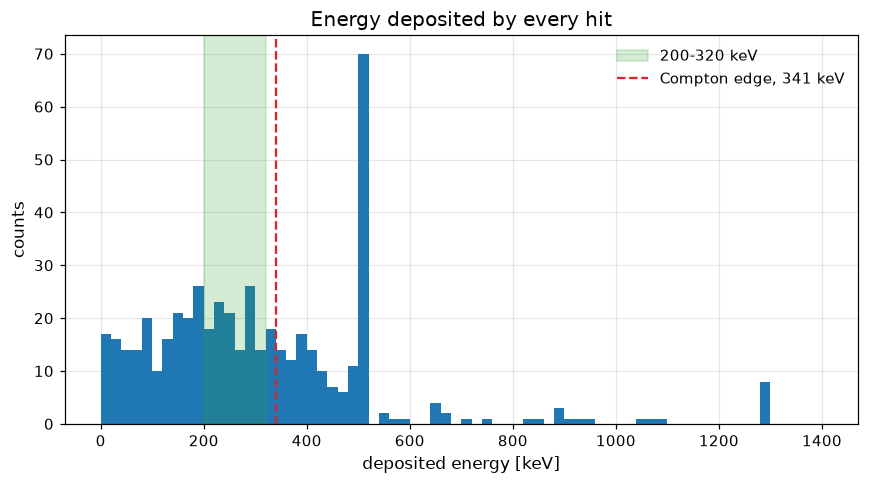

In [4]:
energies = representation.hits_frame([Field.EDEP])["edep"].gate.MeV_to_keV()
axes = plotting.plot_hist_1d(
    energies,
    xrange=(0.0, 1400.0),
    xbins=70,
    xtitle="deposited energy [keV]",
    title="Energy deposited by every hit",
)
axes.axvspan(200.0, 320.0, alpha=0.2, color="tab:green", label="200-320 keV")
axes.axvline(341.0, color="tab:red", linestyle="--", label="Compton edge, 341 keV")
axes.legend();

The peak at 511 keV is the absorption of a whole annihilation gamma, the one at
1300 keV that of a prompt gamma. Below 511 keV the spectrum is flat, and the
window sits in it, under the Compton edge: Compton scatterings and absorptions
that kept only a part of the energy share that region, as the next steps show.

### Every Hit Inside The Window

`edep(between=...)` keeps the hits whose deposited energy lies in the range,
both ends included, and leaves out the tracks and events it empties:

In [5]:
in_window = Analysis().hits().edep(between=window)
kept = in_window.apply(representation)
kept

EventTrackHit(events=67, tracks=96, hits=116)

116 hits of 96 tracks, in 67 of the 115 events. Which processes, and which
kinds of gamma, left them:

In [6]:
hits = kept.hits_frame([Field.PROCESS_NAME, Field.GAMMA_TYPE])
hits["gamma"] = hits["gammaType"].map(lambda value: GammaType(value).name)
pd.crosstab(hits["processName"], hits["gamma"])

gamma,ANNIHILATION,PROMPT,UNKNOWN
processName,,,
Compton,22,7,5
PhotoElectric,67,8,7


Not only Compton scatterings: most hits in the window are photoelectric
absorptions, 67 of them by annihilation gammas, which would deposit 511 keV if
the whole energy of the gamma stayed where it was absorbed. It does not
always. Every row of this file is a gamma:

In [7]:
representation.hits_frame([Field.PDG_ENCODING])["PDGEncoding"].value_counts()

PDGEncoding
22    500
Name: count, dtype: int64

A hit of a gamma records the energy deposited in that step. When the
absorption sets an electron free with energy enough to be followed on its own,
that energy is recorded on the hits of the electron - and those are not in the
file. How often the first absorption of an annihilation gamma kept all 511 keV,
and how often only a part:

In [8]:
everything = representation.hits_frame([Field.PROCESS_NAME, Field.GAMMA_TYPE, Field.EDEP])
first_absorptions = everything[
    (everything["hitNumber"] == 1)
    & (everything["processName"] == "PhotoElectric")
    & (everything["gammaType"] == GammaType.ANNIHILATION)
]
whole = first_absorptions["edep"].gate.MeV_to_keV().round() == 511
int(whole.sum()), int((~whole).sum())

(44, 108)

44 first absorptions kept all 511 keV, and 108 only a part of it. The window
keeps what a detector measuring energy alone would keep, and that includes
partial absorptions. An analysis that needs the Compton scatterings
says so:

In [9]:
compton_in_window = Analysis().hits().process(Process.COMPTON).edep(between=window)
compton_in_window.apply(representation)

EventTrackHit(events=33, tracks=33, hits=34)

And the Compton scatterings of annihilation gammas, against the edge: below
the window, inside it, and above it.

In [10]:
compton = everything[
    (everything["processName"] == "Compton") & (everything["gammaType"] == GammaType.ANNIHILATION)
]
compton_keV = compton["edep"].gate.MeV_to_keV()
below = int((compton_keV < 200).sum())
inside = int(compton_keV.between(200, 320).sum())
above = int((compton_keV > 320).sum())
below, inside, above, round(float(compton_keV.max()), 1)

(97, 22, 4, 354.4)

Most scatterings gave less than 200 keV - small angles are the likelier ones -
and four gave more than 320 keV. The largest is 354 keV, above the Compton edge
of 341 keV: the edge is that of an electron free and at rest, and the electrons
of a material are neither.

### The First Hit Of Every Track

At a position, a condition decides about the track. The tracks whose first
interaction deposited an energy inside the window, with all their hits:

In [11]:
first_in_window = Analysis().hit(1).edep(between=window).apply(representation)
first_in_window

EventTrackHit(events=47, tracks=57, hits=90)

### Both Annihilation Gammas Of An Event

The events in which both annihilation gammas first deposited inside the
window. The closing `tracks(2)` asks for both: without it, an event in which
only one of them did would stay.

In [12]:
both_in_window = (
    Analysis().tracks().gamma_type(GammaType.ANNIHILATION).hit(1).edep(between=window).tracks(2)
)
both_in_window.apply(representation)

EventTrackHit(events=7, tracks=14, hits=15)

Seven events. Their first deposits, in keV, from a table with one row per event:

In [13]:
table = both_in_window.extract(representation, [Field.EDEP, Field.PROCESS_NAME], max_hits=1)
table["t1h1_keV"] = table["t1h1_edep"].gate.MeV_to_keV()
table["t2h1_keV"] = table["t2h1_edep"].gate.MeV_to_keV()
table[["eventID", "t1h1_keV", "t1h1_processName", "t2h1_keV", "t2h1_processName"]]

,eventID,t1h1_keV,t1h1_processName,t2h1_keV,t2h1_processName
0,4,297.035635,PhotoElectric,289.393693,PhotoElectric
1,20,227.323204,PhotoElectric,304.073960,PhotoElectric
2,32,247.281909,PhotoElectric,268.777043,PhotoElectric
3,35,206.927076,PhotoElectric,208.458856,Compton
4,47,285.891145,PhotoElectric,315.564692,PhotoElectric
5,54,293.727040,PhotoElectric,253.718823,PhotoElectric
6,92,289.676934,PhotoElectric,236.265823,PhotoElectric


Every deposit lies between 200 and 320 keV, as asked, and most of them are
partial photoelectric absorptions rather than scatterings - the window was
asked of the energy, not of the process. `max_hits=1` keeps the first hit of
every track only, the one the window was asked of.

### Which Ends Belong To The Window

Both ends belong to a range given with `between`, unless `inclusive` says
otherwise - with the same words as the selectors of the representation:

In [14]:
closed = Analysis().hits().edep(between=window).apply(representation)
open_window = Analysis().hits().edep(between=window, inclusive="neither").apply(representation)
closed.hit_count, open_window.hit_count

(116, 116)

No hit of this file lies exactly on an end, so the two agree here. On values
that can fall on an end - energies rounded by a digitizer, or a window given in
the same rounding as the data - the choice decides which side keeps them.

## Summary

An energy window is a condition on `edep`, written in keV and converted to the
MeV GATE writes. Asked of every hit, of the first hit of every track, or of
both annihilation gammas of an event, it keeps what a detector measuring energy
alone would keep - partial photoelectric absorptions as well as Compton
scatterings - and an analysis that needs one process says so.

## Bibliography

- [Analysis Of Events, Tracks And Hits](https://opengate-gate-tree.readthedocs.io/en/latest/guide/analysis.html)
  — conditions on a field, positions, and the table
- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — the units GATE writes, and converting between keV and MeV
- [PositroniumSource Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html)
  — what `gammaType` means
- A. H. Compton, *A Quantum Theory of the Scattering of X-rays by Light
  Elements*, Phys. Rev. 21, 483 (1923) — the energy a scattered photon gives
  an electron

## Changelog

- v1: written.